# De-noising Feedforward Autoencoder
##### MNIST reconstruction

Import dependencies

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
%matplotlib inline

#### Util functions

function to plot the images after during testing phase

In [2]:
def plot_images(images, title, no_i_x, no_i_y=3):
    fig = plt.figure(figsize=(10, 15))
    fig.canvas.manager.set_window_title(title)
    images = np.array(images).reshape(-1, 28, 28)
    for i in range(no_i_x):
        for j in range(no_i_y):
            ax = fig.add_subplot(no_i_x, no_i_y, no_i_x * j + (i + 1))
            ax.matshow(images[no_i_x * j + i], cmap="gray")
            plt.xticks([])
            plt.yticks([])

            if j == 0 and i == 0:
                ax.set_title("Real")
            elif j == 0 and i == 1:
                ax.set_title("Distorted")
            elif j == 0 and i == 2:
                ax.set_title("Reconstructed")

function to add noise to input data

In [3]:
def add_noise(data, stddev=0.2):
    noise = torch.randn_like(data) * stddev
    return torch.clamp(data + noise, 0.0, 1.0)

seed random number generators

In [4]:
%%capture
torch.manual_seed(42)

<br>Hyper-parameters

In [5]:
learning_rate = 0.001
n_epoch = 10
batch_size = 20
test_disp = 10  # no of images in plot

load the mnist dataset

In [6]:
%%capture
transform = transforms.ToTensor()
train_data = datasets.MNIST(
    root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(
    root='data', train=False, download=True, transform=transform)

split into train and validation sets (90%-10%)

In [7]:
train_set, val_set = random_split(train_data, [0.9, 0.1])


train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

### Neural Network Model
2 Encoder layers + 2 Decoder layers (all dense neural layers)

#### Model

In [8]:
class DenoisingAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 400),
            nn.Sigmoid(),
            nn.Linear(400, 100),
            nn.Tanh()
        )
        self.decoder = nn.Sequential(
            nn.Linear(100, 400),
            nn.Tanh(),
            nn.Linear(400, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        code = self.encoder(x)
        out = self.decoder(code)
        return out


model = DenoisingAutoencoder()

#### Error and Optimizer

In [9]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

#### Start Training

In [10]:
print("*********** Train ***********")

# Epoch-training
for epoch in range(n_epoch):
    # set to trainig mode
    model.train()
    tr_err = []

    for clean_data, _ in train_loader:
        clean_flat = clean_data.view(-1, 28 * 28)
        noisy_data = add_noise(clean_flat)

        # clear gradients
        optimizer.zero_grad()
        # forward pass
        predictions = model(noisy_data)
        # calculate loss
        loss = criterion(predictions, clean_flat)
        # calculate backpropogation gradient 
        loss.backward()
        # update the model weights
        optimizer.step()
        tr_err.append(loss.item())

    # Validation
    model.eval()
    val_errs = []
    with torch.no_grad():
        for clean_val, _ in val_loader:
            clean_val_flat = clean_val.view(-1, 28 * 28)
            noisy_val = add_noise(clean_val_flat)
            val_preds = model(noisy_val)
            val_errs.append(criterion(val_preds, clean_val_flat).item())

    train_err = sum(tr_err) / len(tr_err)
    val_err = sum(val_errs) / len(val_errs)
    print("Epoch:", epoch, " Train-error:", float(train_err),
          " Validation-error:", float(val_err))

*********** Train ***********
Epoch: 0  Train-error: 0.0334546629032465  Validation-error: 0.015276006037990252
Epoch: 1  Train-error: 0.012085362741620176  Validation-error: 0.010221246254319945
Epoch: 2  Train-error: 0.009126087435245237  Validation-error: 0.008499752002147337
Epoch: 3  Train-error: 0.00780039064258475  Validation-error: 0.007575380199899276
Epoch: 4  Train-error: 0.007030809818835998  Validation-error: 0.006936516856464247
Epoch: 5  Train-error: 0.006520786039634711  Validation-error: 0.00647813430832078
Epoch: 6  Train-error: 0.006146659002535873  Validation-error: 0.0061533228618403275
Epoch: 7  Train-error: 0.005862401570710871  Validation-error: 0.0059191003550464905
Epoch: 8  Train-error: 0.005636792187751444  Validation-error: 0.005737812601340314
Epoch: 9  Train-error: 0.005460281653450457  Validation-error: 0.005577376702179512


#### Testing

In [11]:
print("\n*********** Test ***********")

model.eval()
test_errs = []
disp_imgs = []

with torch.no_grad():
    for i, (clean_test, _) in enumerate(test_loader):
        clean_test_flat = clean_test.view(-1, 28 * 28)
        noisy_test = add_noise(clean_test_flat)
        reconstructed = model(noisy_test)
        err = criterion(reconstructed, clean_test_flat)
        test_errs.append(err.item())

        if i == 0:
            for j in range(test_disp):
                disp_imgs.append(clean_test_flat[j].cpu().numpy())
                disp_imgs.append(noisy_test[j].cpu().numpy())
                disp_imgs.append(reconstructed[j].cpu().numpy())

total_test_err = sum(test_errs) / len(test_errs)
print("Test Error: %.8f" % total_test_err)


*********** Test ***********
Test Error: 0.00545471


#### plot output

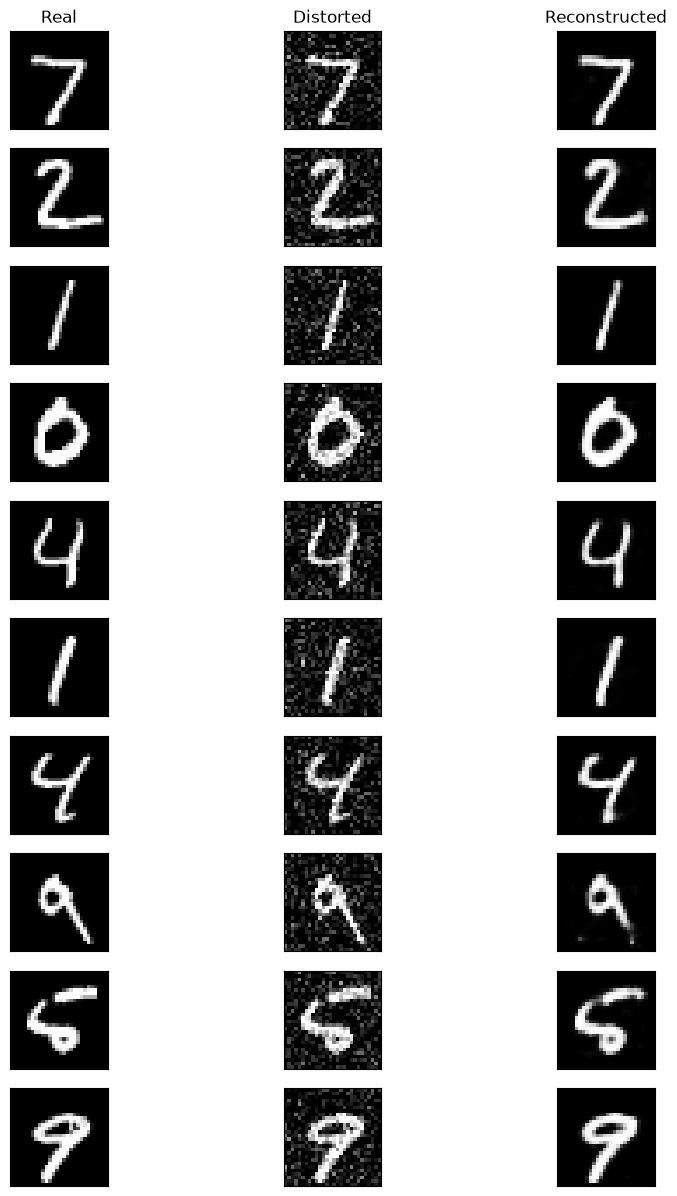

In [12]:
plot_images(disp_imgs, "De-noising Auto-encoder", test_disp)
plt.show()